# Exploratory Data Analysis

In [2]:
# Import packages
import boto3
import duckdb
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

In [3]:
# Access ACLED events data
s3 = boto3.client("s3")
s3.download_file("dsan6000-data", "acled_events.parquet", "events.parquet")

events_con = duckdb.connect()

events_query = """
SELECT * FROM 'events.parquet' LIMIT 5
"""
events_head_df = events_con.execute(events_query).df()

In [3]:
# Show first five events
events_head_df

,event_id_cnty,event_date,year,time_precision,disorder_type,event_type,sub_event_type,actor1,assoc_actor_1,inter1,...,location,latitude,longitude,geo_precision,source,source_scale,notes,fatalities,tags,timestamp
0,RWA3,1997-01-01,1997,1,Political violence,Battles,Armed clash,Military Forces of Rwanda (1994-),None,State forces,...,Gafunzo,-2.3927,29.0044,1,Local Source,International,Security forces kill a rebel officer who had b...,1,None,1618568810
1,ALG1,1997-01-01,1997,1,Political violence,Violence against civilians,Attack,GIA: Armed Islamic Group,None,Rebel group,...,Douaouda,36.6725,2.7894,1,Algeria Watch,Other,5 January: Beheading of 5 citizens in Douaouda...,5,None,1582579226
2,SIE1,1997-01-01,1997,3,Strategic developments,Strategic developments,Looting/property destruction,RUF: Revolutionary United Front,None,Rebel group,...,Magburaka,8.7167,-11.9500,3,SL-LED; No Peace Without Justice,Local partner-New media,Looting,0,None,1607978719
3,SIE4,1997-01-01,1997,3,Strategic developments,Strategic developments,Looting/property destruction,Kamajor Militia,None,Political militia,...,Badjia,7.4338,-12.2419,2,No Peace Without Justice; SL-LED,Local partner-New media,Looting,0,None,1607978767
4,SIE5,1997-01-01,1997,3,Strategic developments,Strategic developments,Looting/property destruction,Kamajor Militia,None,Political militia,...,Valunia,8.3172,-11.7336,2,No Peace Without Justice; SL-LED,Local partner-New media,Looting,0,None,1607978771


In [ ]:
# Column Names and Types
events_con.execute("SELECT * FROM parquet_schema('events.parquet')").df()

,file_name,name,type,type_length,repetition_type,num_children,converted_type,scale,precision,field_id,logical_type,duckdb_type,column_id
0,events.parquet,schema,NaN,None,REQUIRED,31,NaN,<NA>,<NA>,<NA>,NaN,NaN,0
1,events.parquet,event_id_cnty,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,1
2,events.parquet,event_date,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,2
3,events.parquet,year,INT64,None,OPTIONAL,<NA>,NaN,<NA>,<NA>,<NA>,NaN,BIGINT,3
4,events.parquet,time_precision,INT64,None,OPTIONAL,<NA>,NaN,<NA>,<NA>,<NA>,NaN,BIGINT,4
5,events.parquet,disorder_type,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,5
6,events.parquet,event_type,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,6
7,events.parquet,sub_event_type,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,7
8,events.parquet,actor1,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,8
9,events.parquet,assoc_actor_1,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,9


In [13]:
# Look at the split of event types
events_query = """
SELECT "event_type", COUNT(*) AS Count
FROM 'events.parquet'
GROUP BY "event_type"
ORDER BY Count DESC
"""
events_con.sql(events_query).show()

┌────────────────────────────┬─────────┐
│         event_type         │  Count  │
│          varchar           │  int64  │
├────────────────────────────┼─────────┤
│ Protests                   │ 1124970 │
│ Explosions/Remote violence │  498745 │
│ Battles                    │  455519 │
│ Violence against civilians │  320599 │
│ Strategic developments     │  201185 │
│ Riots                      │  180015 │
└────────────────────────────┴─────────┘



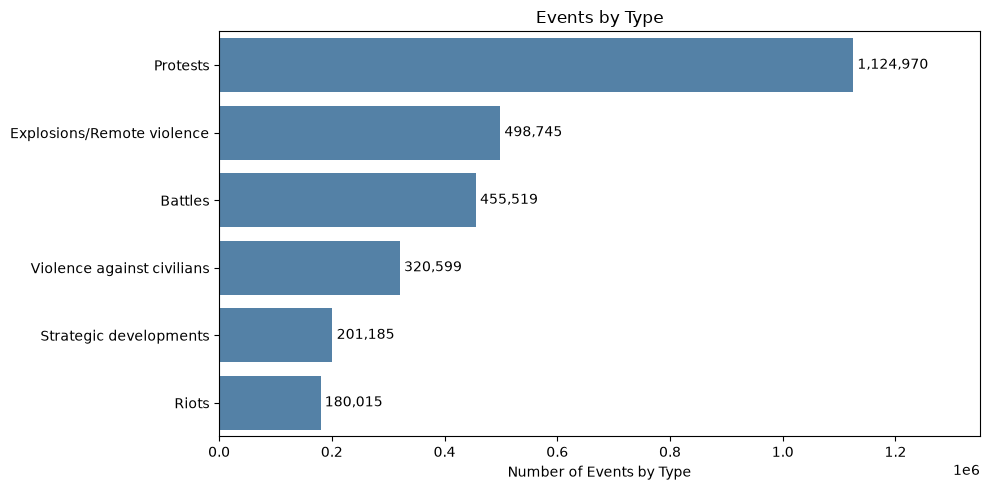

In [ ]:
counts_df = events_con.execute(events_query).df()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=counts_df, x="Count", y="event_type", color="steelblue", ax=ax)

ax.set_xlabel("Number of Events by Type")
ax.set_ylabel("")
ax.set_title("Events by Type")
ax.margins(x=0.2)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)  # count at the end of each bar

plt.tight_layout()
plt.show()

In [19]:
# Look at the split of region events
regions_query = """
SELECT "region", COUNT(*) AS Count
FROM 'events.parquet'
GROUP BY "region"
ORDER BY Count DESC
"""
events_con.sql(regions_query).show()

┌───────────────────────────┬────────┐
│          region           │ Count  │
│          varchar          │ int64  │
├───────────────────────────┼────────┤
│ Middle East               │ 556759 │
│ Europe                    │ 522204 │
│ South Asia                │ 368897 │
│ South America             │ 247885 │
│ North America             │ 208570 │
│ Southeast Asia            │ 157736 │
│ Eastern Africa            │ 140776 │
│ Caucasus and Central Asia │ 109155 │
│ Western Africa            │ 102923 │
│ Northern Africa           │ 101253 │
│ East Asia                 │  81923 │
│ Middle Africa             │  78931 │
│ Central America           │  35185 │
│ Southern Africa           │  34615 │
│ Caribbean                 │  25334 │
│ Oceania                   │   7362 │
│ International Waters      │   1517 │
│ Antarctica                │      8 │
└───────────────────────────┴────────┘
  18 rows                  2 columns



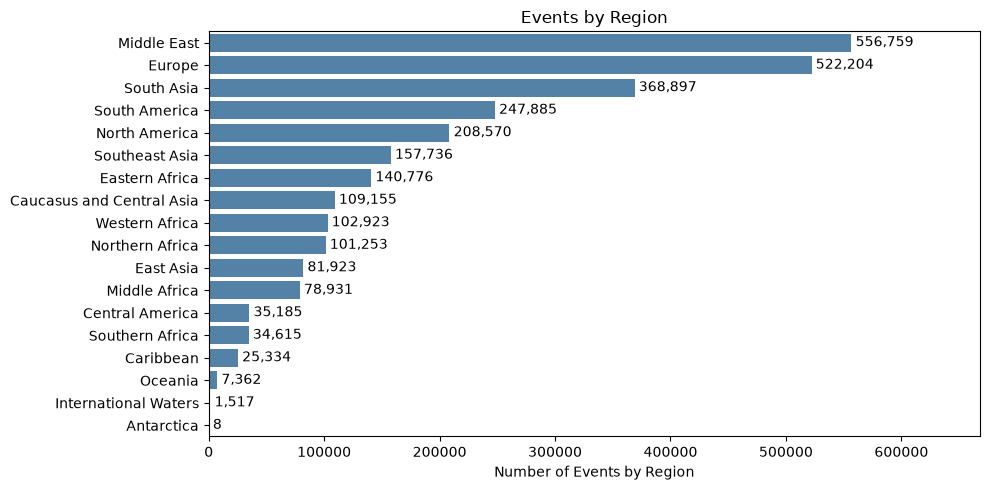

In [20]:
# Plot events by region
regions_df = events_con.execute(regions_query).df()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=regions_df, x="Count", y="region", color="steelblue", ax=ax)

ax.set_xlabel("Number of Events by Region")
ax.set_ylabel("")
ax.set_title("Events by Region")
ax.margins(x=0.2)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)  # count at the end of each bar

plt.tight_layout()
plt.show()

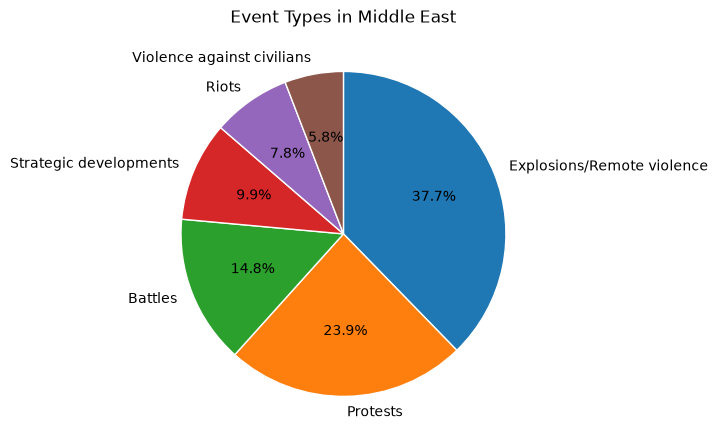

In [28]:
# Look at events in Middle East since it has the most
# (we can reuse this code block for other regions if needed)
region = "Middle East"

me_query = """
SELECT "event_type", COUNT(*) AS Count
FROM 'events.parquet'
WHERE region = ?
GROUP BY "event_type"
ORDER BY Count DESC
"""
me_df = events_con.execute(me_query, [region]).df()

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    me_df["Count"],
    labels=me_df['event_type'],
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white"},
)
ax.set_title(f"Event Types in {region}")
plt.tight_layout()
plt.show()

## NLP EDA

In [10]:
# Data Quality: "notes" Field Coverage
# Computes overall and per-class counts/percentages of rows with a non-empty `notes` field.

notes_quality = events_con.sql("""
    SELECT
        CASE
            WHEN GROUPING(event_type) = 1 THEN 'ALL ROWS (Total)'
            ELSE COALESCE(CAST(event_type AS VARCHAR), 'NULL')
        END AS event_type,
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (
            WHERE COALESCE(trim(CAST(notes AS VARCHAR)), '') != ''
        ) AS has_notes_count,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE COALESCE(trim(CAST(notes AS VARCHAR)), '') != ''
            ) / NULLIF(COUNT(*), 0),
            1
        ) AS has_notes_pct
    FROM 'events.parquet'
    GROUP BY GROUPING SETS ((event_type), ())
    ORDER BY GROUPING(event_type) DESC, has_notes_pct DESC
""").df()

display(notes_quality)

,event_type,total_rows,has_notes_count,has_notes_pct
0,ALL ROWS (Total),2781033,2781033,100.0
1,Protests,1124970,1124970,100.0
2,Riots,180015,180015,100.0
3,Battles,455519,455519,100.0
4,Explosions/Remote violence,498745,498745,100.0
5,Strategic developments,201185,201185,100.0
6,Violence against civilians,320599,320599,100.0


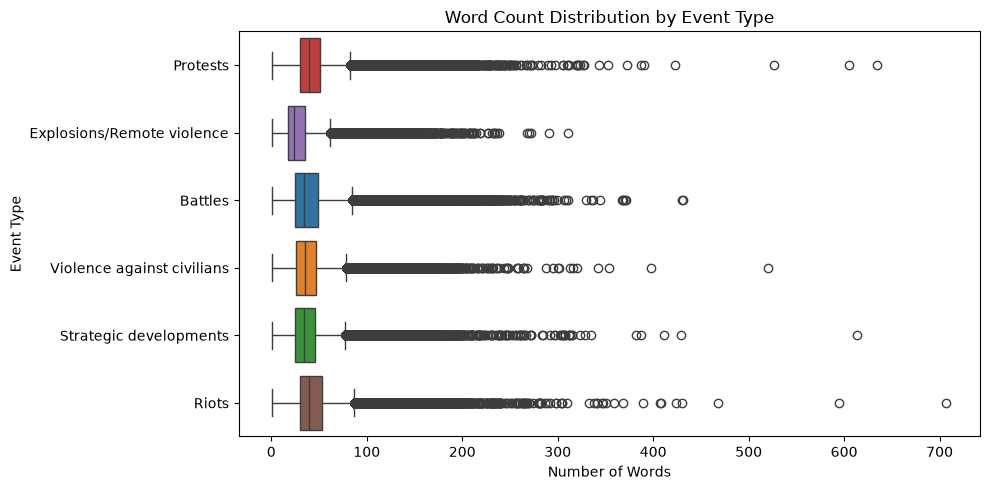

In [11]:
# Class Counts & Word Length Distribution
# Checks for rare classes and documents exceeding ~380 words (~512 tokens).

stats_df = events_con.sql("""
    SELECT
        event_type,
        len(string_split(regexp_replace(trim(notes), '\s+', ' ', 'g'), ' ')) AS word_count
    FROM 'events.parquet'
    WHERE notes IS NOT NULL
""").df()

order = stats_df["event_type"].value_counts().index

fig, axes = plt.subplots(1, 1, figsize=(10, 5))

# Word count per class
sns.boxplot(
    data=stats_df, x="word_count", y="event_type", order=order,
    hue="event_type", legend=False, showfliers=True, ax=axes
)
axes.set_title("Word Count Distribution by Event Type")
axes.set_xlabel("Number of Words")
axes.set_ylabel("Event Type")

plt.tight_layout()
plt.show()

In [ ]:
# Duplicate Text, Conflicting Labels & Start/End Boilerplate
# Catches identical texts assigned different labels and recurring headers/footers.

# Overall exact duplicate summary
dup_summary = events_con.sql("""
    WITH grouped AS (
        SELECT
            notes,
            COUNT(*) AS total_rows,
            COUNT(DISTINCT event_type) AS distinct_event_types
        FROM 'events.parquet'
        WHERE notes IS NOT NULL
        GROUP BY notes
    )
    SELECT
        COALESCE(SUM(total_rows), 0) AS total_rows,
        COUNT(*) AS unique_notes,
        COALESCE(SUM(total_rows - 1), 0) AS extra_duplicate_rows,
        ROUND(
            100.0 * COALESCE(SUM(total_rows - 1), 0) / NULLIF(SUM(total_rows), 0),
            2
        ) AS duplicate_row_pct,
        COUNT(*) FILTER (WHERE total_rows > 1) AS duplicated_unique_notes,
        COUNT(*) FILTER (WHERE total_rows > 1 AND distinct_event_types > 1) AS conflicting_type_notes
    FROM grouped
""").df()

print("=== Overall Exact Duplicate Summary ===")
display(dup_summary)

# Top duplicates & conflicting labels
conflicts = events_con.sql("""
    SELECT
        notes,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT event_type) AS distinct_event_types,
        list(DISTINCT event_type) AS event_types
    FROM 'events.parquet'
    GROUP BY notes
    HAVING COUNT(*) > 1
    ORDER BY distinct_event_types DESC, total_rows DESC
    LIMIT 15
""").df()

print("=== Top Duplicate Texts & Conflicting Labels ===")
display(conflicts)

# Repeated opening & closing snippets per class (boilerplate leakage)
boilerplate = events_con.sql("""
    SELECT
        event_type,
        LEFT(trim(notes), 45) AS start_snippet,
        RIGHT(trim(notes), 45) AS end_snippet,
        COUNT(*) AS freq
    FROM 'events.parquet'
    GROUP BY event_type, start_snippet, end_snippet
    HAVING COUNT(*) >= 3
    ORDER BY freq DESC
    LIMIT 15
""").df()

print("=== Repeated Start / End Snippets ===")
display(boilerplate)

=== Overall Exact Duplicate Summary ===


,total_rows,unique_notes,extra_duplicate_rows,duplicate_row_pct,duplicated_unique_notes,conflicting_type_notes
0,2781033.0,2724391,56642.0,2.04,26492,845


=== Duplicate Texts & Conflicting Labels ===


,notes,total_rows,distinct_event_types,event_types
0,chiefdom uncertain,20,3,"[Strategic developments, Violence against civi..."
1,Report of numerous ground and air attacks by S...,6,3,"[Violence against civilians, Explosions/Remote..."
2,POST-SAVIMBI UNITA ATTACK,5,3,"[Battles, Violence against civilians, Strategi..."
3,Battle between Sudanese forces and SLM/A-Nur e...,5,3,"[Battles, Violence against civilians, Explosio..."
4,"At least 21 people killed, 30 wounded and 127 ...",4,3,"[Battles, Explosions/Remote violence, Protests]"
5,Report of air and ground attack by Sudan soldi...,3,3,"[Explosions/Remote violence, Violence against ..."
6,Battle between Sudanese forces and SLM/A-Nur e...,3,3,"[Battles, Explosions/Remote violence, Violence..."
7,police station,3,3,"[Strategic developments, Violence against civi..."
8,The South African military launches a 600 man ...,3,3,"[Riots, Violence against civilians, Battles]"
9,Three persons were feared dead and several oth...,3,3,"[Violence against civilians, Battles, Riots]"


=== Repeated Start / End Snippets ===


,event_type,start_snippet,end_snippet,freq
0,Strategic developments,Looting,Looting,801
1,Violence against civilians,ZANU-PF assaults civilians,ZANU-PF assaults civilians,453
2,Protests,"On 9 September 2021, workers under the BMS st",t of a nation-wide protest called by the BMS.,270
3,Battles,ONLF attacks Ethiopian soldiers,ONLF attacks Ethiopian soldiers,229
4,Violence against civilians,A drug suspect was killed in a vigilante-styl,d in the Philippine Daily Inquirer Kill List.,217
5,Explosions/Remote violence,The demolition of an explosive device took pl,used. There were 0 injuries and 0 fatalities.,175
6,Protests,"On 5 April 2024, local residents, including M",pital of Damascus and killed 7 IRGC officers.,166
7,Battles,UPDF battles LRA,UPDF battles LRA,153
8,Explosions/Remote violence,"On 23 September 2024, Israeli warplanes carri",rgets throughout the day. Casualties unknown.,147
9,Protests,"On 26 January 2025, following leaked cell pho","xygen', the last words of one of the victims.",145


- extra_duplicate_rows: total number of redundant rows
- duplicated_unique_texts: number of unique text strings that appear 2 or more times
- conflicting_label_texts: subset of duplicated_unique_texts that were assigned two or more different labels

In [6]:
# Distinctive Words & Class Overlap

top_words_df = events_con.sql("""
    WITH sample_docs AS (
        SELECT
            ROW_NUMBER() OVER () AS doc_id,
            CAST(event_type AS VARCHAR) AS event_type,
            regexp_extract_all(lower(CAST(notes AS VARCHAR)), '[a-z]{3,}') AS words
        FROM 'events.parquet'
        WHERE COALESCE(trim(CAST(notes AS VARCHAR)), '') != ''
          AND COALESCE(trim(CAST(event_type AS VARCHAR)), '') != ''
        USING SAMPLE 50000 ROWS
    ),
    doc_words AS (
        SELECT DISTINCT doc_id, event_type, word
        FROM sample_docs, UNNEST(words) AS t(word)
    ),
    word_stats AS (
        SELECT word, COUNT(*) AS doc_freq
        FROM doc_words
        GROUP BY word
        HAVING COUNT(*) >= 5
           AND COUNT(*) < 0.4 * (SELECT COUNT(*) FROM sample_docs)
    ),
    class_totals AS (
        SELECT event_type, COUNT(DISTINCT doc_id) AS class_docs
        FROM sample_docs
        GROUP BY event_type
    ),
    scored AS (
        SELECT
            dw.event_type,
            dw.word,
            COUNT(*) AS class_word_docs,
            (1.0 * COUNT(*) / ct.class_docs) /
            (1.0 * ws.doc_freq / (SELECT COUNT(*) FROM sample_docs)) AS lift
        FROM doc_words dw
        JOIN word_stats ws USING (word)
        JOIN class_totals ct USING (event_type)
        GROUP BY dw.event_type, dw.word, ws.doc_freq, ct.class_docs
        HAVING COUNT(*) >= 3
    )
    SELECT event_type, word, class_word_docs, ROUND(lift, 1) AS lift
    FROM scored
    QUALIFY ROW_NUMBER() OVER (PARTITION BY event_type ORDER BY lift DESC) <= 25
    ORDER BY event_type, lift DESC
""").df()

# Print top 10 distinctive words per class (lift = how much more common than overall)
for cls, grp in top_words_df.groupby("event_type"):
    words = [f"{r.word} ({r.lift}x)" for r in grp.head(10).itertuples()]
    print(f"[{cls}]: {', '.join(words)}")

[Battles]: horikhove (6.0x), qiyameddinli (6.0x), communicator (6.0x), dachenske (6.0x), horadiz (6.0x), battlesaround (6.0x), sngf (6.0x), vodiane (6.0x), samangan (6.0x), vidrodzhennia (6.0x)
[Explosions/Remote violence]: valuyki (5.6x), naddnipryanske (5.6x), terezovka (5.6x), zengil (5.6x), olhivske (5.6x), borova (5.6x), porozok (5.6x), qizan (5.6x), shebekino (5.6x), jazraya (5.6x)
[Protests]: mashhad (2.5x), seong (2.5x), emmanuel (2.5x), kotri (2.5x), chungcheong (2.5x), bodo (2.5x), rep (2.5x), fazilka (2.5x), ecological (2.5x), immigrant (2.5x)
[Riots]: kindia (15.6x), shacks (15.6x), saifi (15.6x), isawiya (15.6x), arrub (15.6x), blasted (15.6x), yatma (15.6x), hizma (15.6x), sorcery (15.6x), bayta (15.6x)
[Strategic developments]: goyim (13.9x), trailer (13.9x), oblasts (13.9x), illnesses (13.9x), captagon (13.9x), sociogenic (13.9x), disposed (13.9x), waleed (13.9x), baofeng (13.9x), detonator (13.9x)
[Violence against civilians]: tiro (8.7x), bulacan (8.7x), bones (8.7x),

The code above shows us that there is lots of location leakage (ie proper nouns dominate) in the notes text.
80–100% of the top words in Battles and Explosions/Remote violence are specific villages and towns (qiyameddinli, aygedzor, nadiivka, veselivka, novostroyevka, ankawi), and Riots is heavily anchored by West Bank towns (hizma, jayyus, qaddum, mughayyir).

Training a classifier on this raw text will memorize geography rather than event mechanics and action words. One thing we can do is filter out words that only ever appear capitalized (a fast, zero-NER way to strip village names and surface the real action verbs).

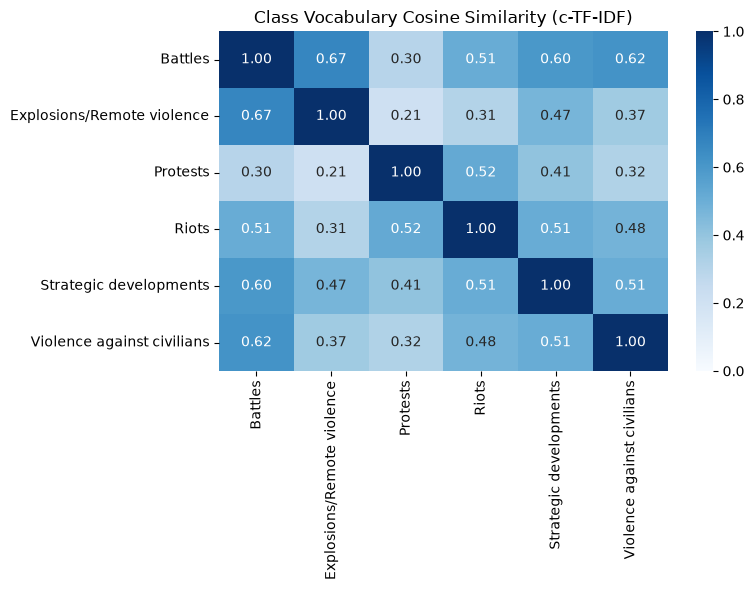

In [9]:
# Class Vocabulary Similarity Heatmap (c-TF-IDF Cosine Similarity)

sim_df = events_con.sql("""
    WITH sample_docs AS (
        SELECT
            ROW_NUMBER() OVER () AS doc_id,
            CAST(event_type AS VARCHAR) AS event_type,
            regexp_extract_all(CAST(notes AS VARCHAR), '[A-Za-z]{3,}') AS raw_words
        FROM 'events.parquet'
        WHERE COALESCE(trim(CAST(notes AS VARCHAR)), '') != ''
          AND COALESCE(trim(CAST(event_type AS VARCHAR)), '') != ''
        USING SAMPLE 50000 ROWS
    ),
    doc_words AS (
        SELECT DISTINCT
            doc_id,
            event_type,
            lower(raw_word) AS word,
            (raw_word = lower(raw_word)) AS is_lowercase
        FROM sample_docs, UNNEST(raw_words) AS t(raw_word)
    ),
    -- Keep content words (drop rare typos, ultra-common stopwords, and proper nouns)
    vocab AS (
        SELECT
            word,
            COUNT(*) AS doc_freq,
            LN(1.0 * (SELECT COUNT(*) FROM sample_docs) / COUNT(*)) AS idf
        FROM doc_words
        GROUP BY word
        HAVING COUNT(*) >= 10
           AND COUNT(*) < 0.4 * (SELECT COUNT(*) FROM sample_docs)
           AND BOOL_OR(is_lowercase)
    ),
    class_totals AS (
        SELECT event_type, COUNT(*) AS total_class_words
        FROM doc_words
        JOIN vocab USING (word)
        GROUP BY event_type
    ),
    class_tfidf AS (
        SELECT
            dw.event_type,
            dw.word,
            (1.0 * COUNT(*) / ct.total_class_words) * v.idf AS weight
        FROM doc_words dw
        JOIN vocab v USING (word)
        JOIN class_totals ct USING (event_type)
        GROUP BY dw.event_type, dw.word, ct.total_class_words, v.idf
    ),
    norms AS (
        SELECT event_type, SQRT(SUM(weight * weight)) AS norm
        FROM class_tfidf
        GROUP BY event_type
    )
    SELECT
        a.event_type AS class_a,
        b.event_type AS class_b,
        ROUND(SUM(a.weight * b.weight) / (na.norm * nb.norm), 2) AS cosine_sim
    FROM class_tfidf a
    JOIN class_tfidf b USING (word)
    JOIN norms na ON a.event_type = na.event_type
    JOIN norms nb ON b.event_type = nb.event_type
    GROUP BY a.event_type, b.event_type, na.norm, nb.norm
""").df()

sim_matrix = (
    sim_df.pivot(index="class_a", columns="class_b", values="cosine_sim")
    .fillna(0.0)
)

plt.figure(figsize=(8, 6))
sns.heatmap(sim_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Class Vocabulary Cosine Similarity (c-TF-IDF)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()